In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data_jobs.csv')
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [2]:
df_US = df[df['job_country'] == 'United States'].copy()

In [4]:
df_US['job_posted_month'] = df_US['job_posted_date'].dt.strftime('%B')

In [17]:
df_US_pivot = df_US.pivot_table(index='job_posted_month', columns='job_title_short', aggfunc='size')

In [18]:
df_US_pivot.reset_index(inplace=True)
df_US_pivot['month_no'] = pd.to_datetime(df_US_pivot['job_posted_month'], format='%B').dt.month
df_US_pivot.sort_values(by='month_no', inplace=True)
df_US_pivot.set_index('job_posted_month', inplace=True)
df_US_pivot.drop(columns='month_no', inplace=True)
df_US_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
January,527,36,8494,2655,6915,60,1544,773,1552,114
February,447,24,6124,3060,4956,56,1258,878,1127,90
March,438,19,6218,3183,4779,59,1114,829,1150,115
April,565,40,6049,2801,4867,51,1025,781,991,112
May,279,20,4993,2976,4377,49,839,746,914,90
June,446,32,5683,2893,4645,48,1009,812,1033,93
July,581,39,5201,2570,4876,65,883,747,1095,153
August,903,39,6634,3269,6318,68,1186,903,1515,194
September,897,50,4639,3224,4568,113,805,775,1014,228


In [19]:
df_US_software_pivot = pd.read_csv('https://lukeb.co/software_csv', index_col='job_posted_month')
df_US_software_pivot

,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
job_posted_month,,,,
January,13619,9827,5108,4348
February,11456,9116,7298,4284
March,11102,8178,5814,4159
April,14037,9209,7232,4220
May,12126,8864,6718,4980
June,12003,8065,5902,4781
July,11914,8061,6839,4344
August,11571,8191,7413,4104
September,14016,8447,6139,4094


In [21]:
df_US_merged = df_US_pivot.merge(df_US_software_pivot, on='job_posted_month', how='inner')
df_US_merged

,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
job_posted_month,,,,,,,,,,,,,,
January,527,36,8494,2655,6915,60,1544,773,1552,114,13619,9827,5108,4348
February,447,24,6124,3060,4956,56,1258,878,1127,90,11456,9116,7298,4284
March,438,19,6218,3183,4779,59,1114,829,1150,115,11102,8178,5814,4159
April,565,40,6049,2801,4867,51,1025,781,991,112,14037,9209,7232,4220
May,279,20,4993,2976,4377,49,839,746,914,90,12126,8864,6718,4980
June,446,32,5683,2893,4645,48,1009,812,1033,93,12003,8065,5902,4781
July,581,39,5201,2570,4876,65,883,747,1095,153,11914,8061,6839,4344
August,903,39,6634,3269,6318,68,1186,903,1515,194,11571,8191,7413,4104
September,897,50,4639,3224,4568,113,805,775,1014,228,14016,8447,6139,4094


In [29]:
top_5 = (
    df_US_merged
    .sum()
    .sort_values(ascending=False)
    .head()
    .index
    .to_list()
)
top_5

['Front-End Developer',
 'Back-End Developer',
 'Full-Stack Developer',
 'Data Analyst',
 'Data Scientist']

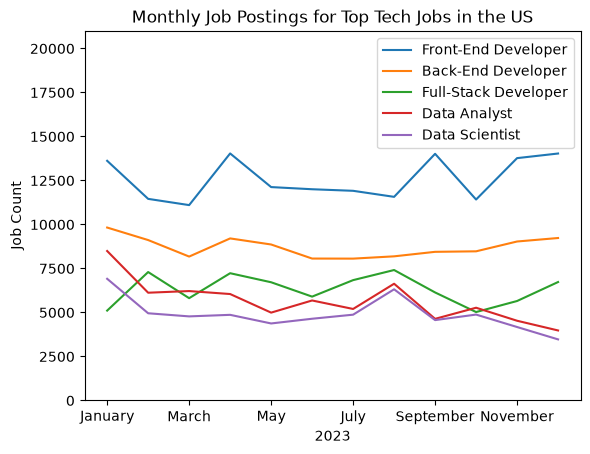

In [85]:
df_US_merged[top_5].plot(kind='line')
plt.title('Monthly Job Postings for Top Tech Jobs in the US')
plt.xlabel('2023')
plt.ylabel('Job Count')
plt.ylim(0, 21000)
plt.legend()
plt.show()

In [71]:
df_us_jobs = df[df['job_country'] == 'United States'].copy()
df_us_jobs['job_posted_month'] = pd.to_datetime(df_us_jobs['job_posted_date'], format='%m').dt.month_name()

df_monthly_postings = df_us_jobs.copy()
df_monthly_postings['job_posted_month'] = df_monthly_postings['job_posted_date'].dt.strftime('%B')
df_monthly_postings = df_monthly_postings.pivot_table(index='job_posted_month', aggfunc='size').rename('count')
df_monthly_postings = df_monthly_postings.reset_index()
df_monthly_postings['month_no'] = pd.to_datetime(df_monthly_postings['job_posted_month'], format='%B').dt.month
df_monthly_postings.sort_values(by='month_no', inplace=True)
df_monthly_postings.drop(columns='month_no', inplace=True)
df_monthly_postings.set_index('job_posted_month', inplace=True)
df_monthly_postings


,count
job_posted_month,
January,22670
February,18020
March,17904
April,17282
May,15283
June,16694
July,16210
August,21029
September,16313


In [77]:
df_us_new = df_us_jobs.merge(df_monthly_postings, on='job_posted_month', how='right')
df_us_new.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month,postings_count
0,Data Scientist,Data Scientist II,Anywhere,via ZipRecruiter,Full-time,True,"New York, United States",2023-04-23 13:02:57,False,False,United States,NaN,NaN,NaN,"Radwell International, LLC","['sql', 'python', 'r', 'mongodb', 'mongodb', '...","{'analyst_tools': ['excel'], 'cloud': ['azure'...",April,17282
1,Data Scientist,"Data Scientist, Data Strategy and Analytics","Alameda, CA",via Trabajo.org,Full-time,False,"California, United States",2023-04-26 13:05:10,False,False,United States,NaN,NaN,NaN,Abbott,NaN,NaN,April,17282
2,Senior Data Scientist,"Mission Data Scientist, Senior - Security Clea...","Fayetteville, NC",via My Panhandle Jobs,Full-time,False,Georgia,2023-04-09 14:21:49,False,True,United States,NaN,NaN,NaN,Booz Allen Hamilton,"['python', 'r', 'postgresql', 'pandas', 'table...","{'analyst_tools': ['tableau', 'splunk'], 'data...",April,17282
3,Data Engineer,Data Engineer,"Las Vegas, NV",via Trabajo.org,Full-time,False,"Illinois, United States",2023-04-28 13:09:58,True,False,United States,NaN,NaN,NaN,Indotronix International Corporation,"['python', 'shell', 'azure', 'databricks', 'ai...","{'cloud': ['azure', 'databricks'], 'libraries'...",April,17282
4,Data Analyst,HR Data Analyst - Remote,Anywhere,via ZipRecruiter,Full-time,True,"California, United States",2023-04-24 13:00:47,False,False,United States,NaN,NaN,NaN,Workoo Technologies,"['sas', 'sas', 'sql']","{'analyst_tools': ['sas'], 'programming': ['sa...",April,17282


In [103]:
df_not_remote_jobs = df[df['job_work_from_home'] == False].copy()
df_not_remote_salary = df_not_remote_jobs.pivot_table(values='salary_year_avg', index='job_title_short', aggfunc='mean').round(2).reset_index().rename(columns = {'salary_year_avg': 'salary_not_remote_avg'})
df_not_remote_salary

df_not_remote_jobs.merge(df_not_remote_salary, on='job_title_short', how='right').head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,salary_not_remote_avg
0,Business Analyst,Technology & Operations Business Analyst,"Copenhagen, Denmark",via Trabajo.org,Full-time,False,Denmark,2023-06-05 13:44:34,False,False,Denmark,NaN,NaN,NaN,Hempel,"['excel', 'powerpoint', 'power bi']","{'analyst_tools': ['excel', 'powerpoint', 'pow...",90177.42
1,Business Analyst,Business Intelligence Intern,"Dallas, TX",via LinkedIn,Full-time,False,"Texas, United States",2023-01-04 13:02:07,False,False,United States,NaN,NaN,NaN,Copart,"['r', 'python', 'sql', 'tableau', 'power bi']","{'analyst_tools': ['tableau', 'power bi'], 'pr...",90177.42
2,Business Analyst,BI Engineer,Namibia,via Intellijobs.ai,Full-time,False,Namibia,2023-03-05 14:10:49,False,False,Namibia,NaN,NaN,NaN,Innover,"['sql', 'gcp', 'looker', 'tableau']","{'analyst_tools': ['looker', 'tableau'], 'clou...",90177.42
3,Business Analyst,Business Analyst,"Tel Aviv-Yafo, Israel",via Comeet,Full-time,False,Israel,2023-09-05 13:50:12,False,False,Israel,NaN,NaN,NaN,ironSource,"['sql', 'excel']","{'analyst_tools': ['excel'], 'programming': ['...",90177.42
4,Business Analyst,Commercial Analyst,South Africa,via LinkedIn,Full-time,False,South Africa,2023-02-14 13:36:23,True,False,South Africa,NaN,NaN,NaN,PEP,"['sql', 'tableau', 'spss', 'sap']","{'analyst_tools': ['tableau', 'spss', 'sap'], ...",90177.42


In [120]:
df_company_salary = df.pivot_table(values='salary_year_avg', index='company_name', aggfunc='mean').round(2).reset_index()
df_company_remote = df[df['job_work_from_home'] == True].copy()
df_company_remote = df_company_remote.groupby('company_name').size().reset_index(name='remote_job_count')
df_company_salary.merge(df_company_remote, on='company_name', how='inner').head()

,company_name,salary_year_avg,remote_job_count
0,#twiceasnice Recruiting,77750.00,1
1,0nward Select,92500.00,1
2,1 Point System,137290.48,1
3,1 Point System LLC.,170000.00,1
4,1872 Consulting,143333.33,2
